In [1]:
from transformers import AutoModel, AutoTokenizer
from transformers import PreTrainedTokenizer

In [46]:
#from cltk.tokenizers.lat.lat import LatinWordTokenizer as WordTokenizer
#from cltk.tokenizers.lat.lat import LatinPunktSentenceTokenizer as SentenceTokenizer
from tensor2tensor.data_generators import text_encoder

* install gdown python library for downloading large files from google drive
* ensure you are in the desired location
* run `gdown "https://drive.google.com/uc?id=1Te_14UB-DZ8wYPhHGyDg7LadDTjNzpti"`
* create a directory for the model where you wish, e.g.: `mkdir -p /srv/models/latin-bert` it might require `sudo`; if the dir is in your repo,  check that you have this path in .gitignore
* unarchive the model to the directory you created: `tar -xf latin_bert.tar --strip-components 1 -C /srv/models/latin-bert`
* download subword tokenizer: `curl -L -o /srv/models/latin-bert/latin.subword.encoder https://github.com/dbamman/latin-bert/raw/master/models/subword_tokenizer_latin/latin.subword.encoder`
* remove the archive you first downloaded: `rm -rf latin_bert.tar`

In [47]:
import os

base_path = "/srv/models/latin-bert"
print(os.path.exists(os.path.join(base_path, "latin_tokenizer.py")))

True


In [48]:
base_path = "/srv/models/latin-bert"

# Initialize the tokenizer with the vocab.txt file and the encoder
vocab_file_path = "/srv/models/latin-bert/vocab.txt" # "/Users/vojtechkase/Projects/latin-bert/models/latin_bert/vocab.txt"  # Update this path
subword_tokenizer_path = "/srv/models/latin-bert/latin.subword.encoder"
# Update this path
encoder = text_encoder.SubwordTextEncoder(subword_tokenizer_path)

spec = importlib.util.spec_from_file_location("latin_tokenizer", os.path.join(base_path, "latin_tokenizer.py"))
latin_tokenizer = importlib.util.module_from_spec(spec)
loader = importlib.util.LazyLoader(spec.loader)
spec.loader.exec_module(latin_tokenizer)

LatinTokenizer = latin_tokenizer.LatinTokenizer

tokenizer = LatinTokenizer(vocab_file_path, encoder)

model = AutoModel.from_pretrained(base_path)

In [49]:
latin_tokenizer

<module 'latin_tokenizer' from '/srv/models/latin-bert/latin_tokenizer.py'>

In [50]:
# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move the model to GPU
model = model.to(device)

In [51]:
sent = "verum ex libro naturae nos hausimus aliqualem illam conformitatem in facultatibus à seminum & aliarum partium similitudine."
input_ids = tokenizer.encode(sent)
tokens = tokenizer.convert_ids_to_tokens(input_ids)
print(tokens)

['verum_', 'ex', 'libro_', 'naturae_', 'nos', 'hausi', 'mus_', 'aliqua', 'lem_', 'illam_', 'conformi', 'tatem_', 'in', 'facultatibus_', 'à', 'semi', 'num_', '&', 'aliarum_', 'partium_', 'similit', 'udin', 'e_', '._']


In [52]:
inputs = tokenizer(sent, return_tensors='pt', padding=True, truncation=True, max_length=512, return_offsets_mapping=True)
input_ids = inputs['input_ids']
input_ids[0][:20] #bert_tokens = tokenizer.convert_ids_to_tokens(input_ids[0].tolist())

tensor([  358,  3641,   651,   601,  4879, 22997,   104, 14893,   649,   557,
        19933,   654,  7556, 26072,  5882,  1950,   310, 31547,  5667,  3464])

# Loading and processing Noscemus textual data

In [53]:
metadata_table_long = pd.read_json("https://raw.githubusercontent.com/CCS-ZCU/noscemus_ETF/master/data/metadata_table_long.json")
# or, if you have noscemus_ETF repository somewhere....
metadata_table_long.head(5)

,Author,Full title,In,Year,Place,Publisher/Printer,Era,Form/Genre,Discipline/Content,Original,...,ids,id,date_min,date_max,filename,file_year,sents_n,tokens_n,disciplines_list,science_class
0,"Achrelius, Daniel",Scientiarum magnes recitatus publice anno 1690...,None,1690,[Turku],Wall,17th century,Oration,"Mathematics, Astronomy/Astrology/Cosmography, ...",Scientiarum magnes(Google Books),...,[705665],705665,1690.0,1690.0,"Achrelius,_Daniel_-_Scientiarum_magnes__Turku_...",1690.0,630,8839,"[Mathematics, Astronomy/Astrology/Cosmography,...",mixture
1,"Acidalius, Valens","Ad Iordanum Brunum Nolanum, Italum","Poematum Iani Lernutii, Iani Gulielmi, Valenti...",1603,"Liegnitz, Wrocław","Albert, David",17th century,Panegyric poem,Astronomy/Astrology/Cosmography,Ad Iordanum Brunum (1603)(CAMENA)Ad Iordanum B...,...,[801745],801745,1603.0,1603.0,Janus_Lernutius_et_al__-_Poemata__Liegnitz_160...,1603.0,6527,82445,[Astronomy/Astrology/Cosmography],exact_sciences
2,"Acosta, José de",De natura novi orbis libri duo et De promulgat...,None,1589,Salamanca,Guillelum Foquel,16th century,Monograph,"Astronomy/Astrology/Cosmography, Geography/Car...",De natura novi orbis(Biodiversity Heritage Lib...,...,[713323],713323,1589.0,1589.0,"Acosta,_José_de_-_De_natura_novi_orbis__Salama...",1589.0,8905,170205,"[Astronomy/Astrology/Cosmography, Geography/Ca...",exact_sciences
3,"Adam, Melchior","Vitae Germanorum medicorum, qui saeculo superi...",None,1620,Heidelberg,"Rosa, Geyder",17th century,Biography,Medicine,Vitae Germanorum medicorum(MDZ)Alternative lin...,...,[693148],693148,1620.0,1620.0,"Adam,_Melchior_-_Vitae_Germanorum_medicorum__H...",1620.0,17961,193272,[Medicine],life_sciences
4,"Addison, Joseph",Ad insignissimum virum dominum Thomam Burnettu...,"Examen poeticum duplex, sive, Musarum anglican...",1698,London,Richard Wellington I.,17th century,Panegyric poem,Meteorology/Earth sciences,Ad Burnettum sacrae theoriae telluris auctorem...,...,[769230],769230,1698.0,1698.0,Examen_poeticum_duplex__London_1698_pdf.txt,1698.0,3533,47878,[Meteorology/Earth sciences],exact_sciences


In [54]:
id_year_dict = dict(zip(metadata_table_long["id"].astype(str), metadata_table_long["file_year"]))

In [55]:
id_author_dict = dict(zip(metadata_table_long["id"].astype(str), metadata_table_long["Author"].apply(lambda x: x.partition(",")[0])))

## Target sentences extraction - skip to next

In [56]:
def get_sentence_data(source_name, target_lemma, target_pos, path):
    target_sentences = []  
    fns = os.listdir(path)
    for fn in fns:
        sents_data = json.load(open(path + fn, "rb"))
        for doc_id, sent_n, sent_text, sent_data in sents_data:
            if source_name == "emlap":
                for tok, lemma, pos, i, page, blocks in sent_data:
                    if lemma == target_lemma and pos == target_pos:
                        sent = [source_name] + sents_data[sent_n]
                        target_sentences.append(sent)
                        break
            if source_name in ["noscemus", "cc"]:
                for tok, lemma, pos, i in sent_data:
                    if lemma == target_lemma and pos == target_pos:
                        sent = [source_name] + sents_data[sent_n]
                        target_sentences.append(sent)
                        break
    return target_sentences

In [57]:
target_lemma = "mercurius"
target_pos = "NOUN"

In [58]:
%%time
tar_sents_emlap = get_sentence_data("emlap", target_lemma, target_pos, "/srv/data/tome/tome-corpus/sents_data_ids_jsons_v3-0/")
tar_sents_noscemus = get_sentence_data("noscemus", target_lemma, target_pos, "/srv/data/tome/noscemus/sents_data_jsons/")

CPU times: user 1min 55s, sys: 4.73 s, total: 2min
Wall time: 2min 6s


In [42]:
tar_sents_emlap[:10]

[['tome',
  100044,
  116,
  'mercuiumpone mercurium pag. 2.',
  [['mercuiumpone', 'mercuiumpo', 'NOUN', [0, 12], [15], [1, 2]],
   ['mercurium', 'mercurius', 'NOUN', [13, 22], [15], [2]],
   ['pag', 'pagicus', 'VERB', [23, 26], [15], [2]],
   ['.', '.', 'PUNCT', [26, 27], [15], [2]],
   ['2', '2', 'NUM', [28, 29], [15], [2]],
   ['.', '.', 'PUNCT', [29, 30], [15], [2]]]],
 ['tome',
  100044,
  624,
  'Elementum mercurii, & separa purum ab impuro.',
  [['Elementum', 'elementum', 'NOUN', [0, 9], [31], [2]],
   ['mercurii', 'mercurius', 'NOUN', [10, 18], [31], [2]],
   [',', ',', 'PUNCT', [18, 19], [31], [2]],
   ['&', '&', 'PUNCT', [20, 21], [31], [2]],
   ['separa', 'separo', 'VERB', [22, 28], [31], [2]],
   ['purum', 'purus', 'ADJ', [29, 34], [31], [2]],
   ['ab', 'ab', 'ADP', [35, 37], [31], [3]],
   ['impuro', 'impurus', 'NOUN', [38, 44], [31], [3]],
   ['.', '.', 'PUNCT', [44, 45], [31], [3]]]],
 ['tome',
  100044,
  634,
  'Hoc peracto, habebis mercurium uitae, quo renouantur & re

In [25]:
len(tar_sents_emlap)

3909

In [59]:
tar_sents_noscemus[:3]

[['noscemus',
  '795551',
  6971,
  'p. 168. (mercurio dulci, topice sanatus.',
  [['p.', 'p.', 'PROPN', [0, 2]],
   ['168', '168', 'PUNCT', [3, 6]],
   ['.', '.', 'PUNCT', [6, 7]],
   ['(', '(', 'PUNCT', [8, 9]],
   ['mercurio', 'mercurius', 'NOUN', [9, 17]],
   ['dulci', 'dulcis', 'ADJ', [18, 23]],
   [',', ',', 'PUNCT', [23, 24]],
   ['topice', 'topix', 'NOUN', [25, 31]],
   ['sanatus', 'sano', 'VERB', [32, 39]],
   ['.', '.', 'PUNCT', [39, 40]]]],
 ['noscemus',
  '795551',
  11325,
  'n. 208. (mercurius?',
  [['n.', '', 'NUM', [0, 2]],
   ['208', '208', 'VERB', [3, 6]],
   ['.', '.', 'PUNCT', [6, 7]],
   ['(', '(', 'PUNCT', [8, 9]],
   ['mercurius', 'mercurius', 'NOUN', [9, 18]],
   ['?', '?', 'PUNCT', [18, 19]]]],
 ['noscemus',
  '795551',
  14173,
  'n. 2. (excrescentiae carniformes post uariolam - mercurio cedentes.',
  [['n.', 'n.', 'NUM', [0, 2]],
   ['2', '2', 'NUM', [3, 4]],
   ['.', '.', 'PUNCT', [4, 5]],
   ['(', '(', 'PUNCT', [6, 7]],
   ['excrescentiae', 'excrescentia', 

In [25]:
%%time
tar_sents_cc = get_sentence_data("cc", target_lemma, target_pos, "/srv/data/corpus-corporum/cc_sents_jsons/")

CPU times: user 40min 14s, sys: 19.2 s, total: 40min 33s
Wall time: 40min 47s


In [26]:
len(tar_sents_cc)

356089

In [27]:
tar_sents = tar_sents_emlap + tar_sents_noscemus + tar_sents_cc
pickle.dump(tar_sents, open("../data/liber_sents_data.pkl", "wb"))

In [67]:
tar_sents = pickle.load(open("../data/liber_sents_data.pkl", "rb"))
tar_sents[:5]

[['tome',
  '100044',
  29,
  'Cum itaque uideret eos ab hominibus doctos, & non ex luce naturae (quae diuinum lumen est, in hunc magnum mundum usquequaque suum splendorem exercens,) speculum hoc ipsis ob oculos ponit, ut ex eo, non secus atque ex libro, cernere, discere atque bonum inter ac malum, discernere, ut uerum a falso, ualerent exactius & per fectius, quam ex tam uariis doctorum suorum scriptis potuerunt hactenus.',
  [['Cum', 'cum', 'SCONJ', [0, 3]],
   ['itaque', 'itaque', 'PART', [4, 10]],
   ['uideret', 'uideo', 'VERB', [11, 18]],
   ['eos', 'is', 'PRON', [19, 22]],
   ['ab', 'ab', 'ADP', [23, 25]],
   ['hominibus', 'homo', 'NOUN', [26, 35]],
   ['doctos', 'doceo', 'VERB', [36, 42]],
   [',', ',', 'PUNCT', [42, 43]],
   ['&', '&', 'PUNCT', [44, 45]],
   ['non', 'non', 'PART', [46, 49]],
   ['ex', 'ex', 'ADP', [50, 52]],
   ['luce', 'lux', 'NOUN', [53, 57]],
   ['naturae', 'natura', 'NOUN', [58, 65]],
   ['(', '(', 'PUNCT', [66, 67]],
   ['quae', 'qui', 'PRON', [67, 71]],
 

In [68]:
len(tar_sents)

525470

In [94]:
text = "et librum naturae et liber scripturae"
re.search(r"lib\w{2,3} naturae", text)

<re.Match object; span=(3, 17), match='librum naturae'>

In [69]:
#tar_sents_volumen = get_sentence_data("uolumen")
#len(tar_sents_volumen)

In [95]:
sents_meta = [sent_data for sent_data in tar_sents if re.search(r"lib\w{2,3} naturae",  sent_data[3].lower())]
sents_meta[:5]

[['tome',
  '100038',
  10852,
  'Quare in legendis philosophorum libris naturae possibilitatem in primis considera:',
  [['Quare', 'quare', 'ADV', [0, 5]],
   ['in', 'in', 'ADP', [6, 8]],
   ['legendis', 'legendus', 'VERB', [9, 17]],
   ['philosophorum', 'philosophus', 'NOUN', [18, 31]],
   ['libris', 'liber', 'NOUN', [32, 38]],
   ['naturae', 'natura', 'NOUN', [39, 46]],
   ['possibilitatem', 'possibilitas', 'NOUN', [47, 61]],
   ['in', 'in', 'ADP', [62, 64]],
   ['primis', 'primus', 'ADJ', [65, 71]],
   ['considera', 'considero', 'VERB', [72, 81]],
   [':', ':', 'PUNCT', [81, 82]]]],
 ['tome',
  '100040',
  1238,
  'Et non habeas taedium in ipso nutriendo, et nefestines, quia scriptum est, Qui patientiam in opere non habet, & non inspicit in nostris libris naturae mutationem, ille propter festinantiam corrumpit opus:',
  [['Et', 'et', 'CCONJ', [0, 2]],
   ['non', 'non', 'PART', [3, 6]],
   ['habeas', 'habeo', 'VERB', [7, 13]],
   ['taedium', 'taedium', 'NOUN', [14, 21]],
   ['in', '

In [96]:
[el for el in sents_meta if el[0]=="cc"]

[['cc',
  '7432',
  9274,
  'At si uniuersam creaturam ita prius aspiceres, ut auctori Deo tribueres, quasi legens magnum quemdam librum naturae rerum;',
  [['At', 'at', 'CCONJ', [0, 2]],
   ['si', 'si', 'SCONJ', [3, 5]],
   ['uniuersam', 'uniuersus', 'ADJ', [6, 15]],
   ['creaturam', 'creatura', 'NOUN', [16, 25]],
   ['ita', 'ita', 'ADV', [26, 29]],
   ['prius', 'prior', 'ADV', [30, 35]],
   ['aspiceres', 'aspicio', 'VERB', [36, 45]],
   [',', ',', 'PUNCT', [45, 46]],
   ['ut', 'ut', 'SCONJ', [47, 49]],
   ['auctori', 'auctor', 'NOUN', [50, 57]],
   ['Deo', 'Deus', 'PROPN', [58, 61]],
   ['tribueres', 'tribuo', 'VERB', [62, 71]],
   [',', ',', 'PUNCT', [71, 72]],
   ['quasi', 'quasi', 'ADV', [73, 78]],
   ['legens', 'legens', 'VERB', [79, 85]],
   ['magnum', 'magnus', 'ADJ', [86, 92]],
   ['quemdam', 'quidam', 'DET', [93, 100]],
   ['librum', 'liber', 'NOUN', [101, 107]],
   ['naturae', 'natura', 'NOUN', [108, 115]],
   ['rerum', 'res', 'NOUN', [116, 121]],
   [';', ';', 'PUNCT', [121

In [97]:
Counter([el[0] for el in sents_meta])

Counter({'noscemus': 67, 'cc': 3, 'tome': 2})

In [98]:
with open("../data/liber_sents_data.json", "w") as f:
    json.dump(sents_meta, f)

In [19]:
with open("../data/liber_sents_data.json", "r") as f:
    sents_meta = json.load(f)

In [21]:
len(sents_meta)

72

In [24]:
[sent_data for sent_data in sents_meta if sent_data[0] == "cc"]

[['cc',
  '7432',
  9274,
  'At si uniuersam creaturam ita prius aspiceres, ut auctori Deo tribueres, quasi legens magnum quemdam librum naturae rerum;',
  [['At', 'at', 'CCONJ', [0, 2]],
   ['si', 'si', 'SCONJ', [3, 5]],
   ['uniuersam', 'uniuersus', 'ADJ', [6, 15]],
   ['creaturam', 'creatura', 'NOUN', [16, 25]],
   ['ita', 'ita', 'ADV', [26, 29]],
   ['prius', 'prior', 'ADV', [30, 35]],
   ['aspiceres', 'aspicio', 'VERB', [36, 45]],
   [',', ',', 'PUNCT', [45, 46]],
   ['ut', 'ut', 'SCONJ', [47, 49]],
   ['auctori', 'auctor', 'NOUN', [50, 57]],
   ['Deo', 'Deus', 'PROPN', [58, 61]],
   ['tribueres', 'tribuo', 'VERB', [62, 71]],
   [',', ',', 'PUNCT', [71, 72]],
   ['quasi', 'quasi', 'ADV', [73, 78]],
   ['legens', 'legens', 'VERB', [79, 85]],
   ['magnum', 'magnus', 'ADJ', [86, 92]],
   ['quemdam', 'quidam', 'DET', [93, 100]],
   ['librum', 'liber', 'NOUN', [101, 107]],
   ['naturae', 'natura', 'NOUN', [108, 115]],
   ['rerum', 'res', 'NOUN', [116, 121]],
   [';', ';', 'PUNCT', [121

## Loading Latin translator

In [55]:
# for preprocessing the latin texts, we will use a module located outside of the current repository, specifically at the same level
current_working_directory = os.getcwd()
relative_path = '../../latin-preprocessing/'  # change according to your location...
module_path = os.path.abspath(os.path.join(current_working_directory, relative_path))
if module_path not in sys.path:
    sys.path.insert(0, module_path)
# Now import the module
import tomela

In [61]:
importlib.reload(tomela)
importlib.reload(tomela.translator)

CuPy is able to use the GPU.
GPU is available for SpaCy.


<module 'tomela.translator' from '/home/jupyter-vojta/notebooks/latin-preprocessing/tomela/translator.py'>

In [62]:
from tomela.translator import translator

In [63]:
# Example Latin text
latin_text = "Veni, vidi, vici."
translator(latin_text)

'Come on, I saw it, I saw it, I saw it.'

# Generating embeddings

In [99]:
def get_decontextualized_embeddings(word: str):
    input_ids = tokenizer.encode(word) # , add_special_tokens=False)
    input_ids_tensor = torch.LongTensor(input_ids).to(device)  # Move to GPU
    word_emb = model.get_input_embeddings()
    embeddings = word_emb(input_ids_tensor)
    return embeddings.mean(0).cpu().detach().numpy()

def compute_offsets(text, tokens):
    """
    Compute character offsets for each token in the original text.
    """
    offsets = []
    current_pos = 0
    for token in tokens:
        # Handle leading spaces and special characters
        token = token.replace("Ġ", "")
        start_idx = text.find(token, current_pos)
        if start_idx == -1:
            # Token not found, possibly a split token or special case
            # Attempt to find token by removing special characters
            cleaned_token = token.replace('_', '')
            start_idx = text.find(cleaned_token, current_pos)
            if start_idx != -1:
                end_idx = start_idx + len(cleaned_token)
                offsets.append((start_idx, end_idx))
                current_pos = end_idx
            else:
                # If still not found, append a dummy offset
                offsets.append((current_pos, current_pos + len(token)))
        else:
            end_idx = start_idx + len(token)
            offsets.append((start_idx, end_idx))
            current_pos = end_idx

    return offsets
    
def get_embeddings_data(sent, tokenized_data):
    sent = sent.lower()
    # Tokenize and prepare input tensors
    inputs = tokenizer(sent, return_tensors='pt', padding=True, truncation=True, max_length=512) #return_offsets_mapping=True)

    input_ids_tensor = inputs['input_ids'].to(device)  # Move to GPU
    attention_mask_tensor = inputs.get('attention_mask', torch.ones_like(input_ids_tensor)).to(device)  # Move to GPU

    # Convert input IDs to tokens
    bert_tokens = tokenizer.convert_ids_to_tokens(input_ids_tensor[0].tolist())
    offset_mapping = compute_offsets(sent, bert_tokens)

    # Model forward pass
    with torch.no_grad():
        outputs = model(input_ids=input_ids_tensor, attention_mask=attention_mask_tensor)
        last_hidden_state = outputs.last_hidden_state
        bert_sentence_embeddings = last_hidden_state.mean(dim=1).squeeze().cpu().detach().numpy()  # Move back to CPU
        bert_token_embeddings = last_hidden_state[0].cpu().detach().numpy()  # Move back to CPU

    # Prepare tokens data for comparison
    tokens_data_updated = [(token, offset, embedding) for token, offset, embedding in zip(bert_tokens, offset_mapping, bert_token_embeddings)]

    covered_tups = []
    for word_tuple in tokenized_data:
        start_offset, end_offset = word_tuple[-1]
    
        # Extract covered tokens and embeddings
        covered_tokens = [tup[0] for tup in tokens_data_updated if start_offset <= tup[1][0] < end_offset]
        covered_embeddings = [tup[2] for tup in tokens_data_updated if start_offset <= tup[1][0] < end_offset]
    
        # Compute average embedding
        if covered_embeddings:
            embedding_avg = np.mean(covered_embeddings, axis=0)
        else:
            embedding_avg = np.zeros(768)
    
        # Decontextualized embedding
        embedding_decontext = get_decontextualized_embeddings(word_tuple[0])
    
        # Compute similarity score
        embedding_avg_2d = embedding_avg.reshape(1, -1)
        embedding_decontext_2d = embedding_decontext.reshape(1, -1)
        if np.isnan(embedding_avg).any() or np.isnan(embedding_decontext).any():
            similarity_score = None
        else:
            similarity_score = cosine_similarity(embedding_avg_2d, embedding_decontext_2d)[0, 0]
    
        # Append to results
        covered_tups.append((
            word_tuple[0],    # spacy_tokens
            word_tuple[1],    # spacy_lemma
            word_tuple[2],    # spacy_pos
            word_tuple[3],    # spacy_position
            covered_tokens,   # bert_tokens
            covered_embeddings, # bert_tok_emb
            embedding_avg.tolist(),   # Convert numpy array to list
            embedding_decontext.tolist(), # Convert numpy array to list
            similarity_score # cos_sim
        ))
    
    # Create DataFrame
    df = pd.DataFrame(covered_tups, columns=[
        "spacy_tokens", "spacy_lemma", "spacy_pos", "spacy_position",
        "bert_tokens", "bert_tok_emb", "bert_avg_emb", "bert_avg_decontext", "cos_sim"
    ])

    return bert_sentence_embeddings, df

In [113]:
sent_n = 8
sent = sents_meta[sent_n][3].lower()
tokenized_data = sents_meta[sent_n][4]
sent

'sedulo itaque demus operam, ut deum recte cognoscamus, idque ex libro naturae & scripturae, ex lege & euangelio, ex u. & n. t. ex bibliis paruis & magnis: 30 ut, inquam, cognoscamus ipsius tum essentiam unam, spiritualem, aeternam & omnipotentem, in qua uere & realiter distinctae sunt tres personae:'

In [107]:
translator(sent)

'Itaque sedulo dem operam, so that we may have a right to know, like the book nature & scripture, ex lege & euangelio, ex u. & n. t. ex bibliis paruis & magnis: 30 so that, in what, we know ipsius tum essentiam unam, spiritual, aeteram & omnipotentem, in which the three persons are distinct reality:'

In [108]:
inputs = tokenizer(sent, return_tensors='pt', padding=True, truncation=True, max_length=512) #return_offsets_mapping=True)
inputs

{'input_ids': tensor([[28138,   346, 20096,  1731,     7,  2486,   244,   569,  9915,   104,
              7,  1970,    35,  3641,   651,   601, 31547,  3201,     7,  3641,
          24539, 31547, 22634,    24,     7,  3641,   117,     8, 31547,   121,
              8,    29,     8,  3641,  9758,    37, 19326,    14, 31547,  2451,
             17,  6185,    31,     7,  1733,     7,  9915,   104,   417,  5596,
           1955,   842,     7,  8040,     7,  3179, 31547, 28731,     7,  7556,
           2824, 15419, 31547, 28963, 26615,    23,  9955,   564,  1584,    17,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,    

In [109]:
input_ids = tokenizer.encode(sent)
tokens = tokenizer.convert_ids_to_tokens(input_ids)
tokens

['sedulo_',
 'itaque_',
 'demus_',
 'operam_',
 ',_',
 'ut',
 'deum_',
 'recte_',
 'cognosca',
 'mus_',
 ',_',
 'id',
 'que_',
 'ex',
 'libro_',
 'naturae_',
 '&',
 'scripturae_',
 ',_',
 'ex',
 'lege',
 '&',
 'euangeli',
 'o_',
 ',_',
 'ex',
 'u_',
 '._',
 '&',
 'n_',
 '._',
 't_',
 '._',
 'ex',
 'bibli',
 'is_',
 'parui',
 's_',
 '&',
 'magnis_',
 ':_',
 '30',
 'ut_',
 ',_',
 'inquam_',
 ',_',
 'cognosca',
 'mus_',
 'ipsius_',
 'tum',
 'essentiam_',
 'unam_',
 ',_',
 'spiritualem_',
 ',_',
 'aeternam_',
 '&',
 'omnipotentem_',
 ',_',
 'in',
 'qua',
 'uere',
 '&',
 'realiter_',
 'distincta',
 'e_',
 'sunt',
 'tres_',
 'personae_',
 ':_']

In [114]:
sentence_emb, df = get_embeddings_data(sent.lower(), tokenized_data)
df

,spacy_tokens,spacy_lemma,spacy_pos,spacy_position,bert_tokens,bert_tok_emb,bert_avg_emb,bert_avg_decontext,cos_sim
0,Sedulo,sedulus,ADV,"[0, 6]",[sedulo_],"[[-0.072932504, 0.14378202, -0.32978356, -0.82...","[-0.07293250411748886, 0.14378201961517334, -0...","[0.023064322769641876, -0.050751522183418274, ...",0.025346
1,itaque,itaque,PART,"[7, 13]",[itaque_],"[[-0.033511367, 0.11423109, -0.4176859, -0.290...","[-0.033511366695165634, 0.11423108726739883, -...","[-0.024233810603618622, -0.03258190676569939, ...",0.105038
2,demus,do,VERB,"[14, 19]",[demus_],"[[-0.0025911373, -0.002883042, 0.14300738, -0....","[-0.002591137308627367, -0.00288304197601974, ...","[0.07120110094547272, -0.021780237555503845, -...",0.076196
3,operam,opera,NOUN,"[20, 26]",[operam_],"[[-0.18491435, 0.34907225, 0.39900115, -0.2379...","[-0.18491435050964355, 0.34907224774360657, 0....","[-0.07032217085361481, 0.0306769497692585, 0.1...",0.154257
4,",",",",PUNCT,"[26, 27]","[,_]","[[-0.47928557, 0.013977119, -0.25940102, -0.60...","[-0.4792855679988861, 0.013977118767797947, -0...","[0.030093882232904434, -0.11158721148967743, 0...",-0.006341
...,...,...,...,...,...,...,...,...,...
56,distinctae,distinguo,VERB,"[270, 280]","[distincta, e_]","[[-0.3344154, -0.15519957, -0.5695672, -0.4008...","[-0.37701791524887085, -0.27655133605003357, -...","[0.015920359641313553, 0.016091614961624146, -...",0.188532
57,sunt,sum,AUX,"[281, 285]",[sunt],"[[0.011679635, 0.08291831, -0.31473458, -0.651...","[0.011679635383188725, 0.08291830867528915, -0...","[0.10326463729143143, 0.023568930104374886, -0...",0.078459
58,tres,tres,NUM,"[286, 290]",[tres_],"[[-0.34024152, 0.027422084, 0.030938901, -1.28...","[-0.34024152159690857, 0.027422083541750908, 0...","[0.01127949170768261, 0.03904206305742264, 0.0...",0.168788
59,personae,persona,NOUN,"[291, 299]",[personae_],"[[-0.14587805, 0.042621147, -0.5177622, -0.075...","[-0.14587804675102234, 0.04262114688754082, -0...","[-0.008275933563709259, 0.01998576894402504, 0...",0.096017


In [115]:
n = 2000
tar_sents_sample = random.sample(tar_sents, n)

In [32]:
sents_meta[0]

('704336.pickle',
 29989,
 'omnes hi cum lanne & Mambre et Simone mago aeternis ignibus cruciandi destinabuntur. 99 In primo libro naturalis magia traditur, quae multa sane cognitu pulchra & iucun da lectu continet:',
 [('omnes', 'omnis', 'DET', (0, 5)),
  ('hi', 'hic', 'DET', (6, 8)),
  ('cum', 'cum', 'ADP', (9, 12)),
  ('lanne', '', 'NOUN', (13, 18)),
  ('&', '&', 'PUNCT', (19, 20)),
  ('Mambre', '', 'PROPN', (21, 27)),
  ('et', 'et', 'CCONJ', (28, 30)),
  ('Simone', 'Simo', 'PROPN', (31, 37)),
  ('mago', 'magus', 'NOUN', (38, 42)),
  ('aeternis', 'aeternus', 'ADJ', (43, 51)),
  ('ignibus', 'ignis', 'NOUN', (52, 59)),
  ('cruciandi', 'crucio', 'VERB', (60, 69)),
  ('destinabuntur', 'destino', 'VERB', (70, 83)),
  ('.', '.', 'PUNCT', (83, 84)),
  ('99', '99', 'NUM', (85, 87)),
  ('In', 'in', 'ADP', (88, 90)),
  ('primo', 'primus', 'ADJ', (91, 96)),
  ('libro', 'liber', 'NOUN', (97, 102)),
  ('naturalis', 'naturalis', 'ADJ', (103, 112)),
  ('magia', 'magia', 'NOUN', (113, 118)),
  ('tr

In [116]:
%%time
sents_dfs = []
for sent_data in sents_meta + tar_sents_sample:
    sent_emb, df = get_embeddings_data(sent_data[3], sent_data[4])
    sents_dfs.append((sent_data[0], sent_data[1], sent_data[2], sent_data[3], sent_emb, df))

CPU times: user 47.7 s, sys: 1.64 s, total: 49.4 s
Wall time: 49.3 s


## Read metadata for works

In [117]:
noscemus_metadata = pd.read_csv("/srv/data/tome/noscemus/metadata_table_long.csv")
tome_metadata = pd.read_json("/srv/data/tome/tome-corpus/tome_metadata_v2-0.json")
cc_metadata = pd.read_json("/srv/data/corpus-corporum/cc_metadata.json")

In [133]:
noscemus_metadata.columns

Index(['Author', 'Full title', 'In', 'Year', 'Place', 'Publisher/Printer',
       'Era', 'Form/Genre', 'Discipline/Content', 'Original',
       'Digital sourcebook', 'Description', 'References', 'Cited in',
       'How to cite this entry', 'Internal notes', 'Of interest to',
       'Transkribus text available', 'Written by', 'Library and Signature',
       'ids', 'id', 'date_min', 'date_max', 'filename', 'file_year'],
      dtype='object')

In [134]:
noscemus_year_dict = dict(zip(noscemus_metadata["id"], noscemus_metadata["file_year"]))
noscemus_author_dict = dict(zip(noscemus_metadata["id"], noscemus_metadata["Author"].apply(lambda x: x.partition(",")[0])))

In [126]:
tome_metadata.head(5)

,No.,is_noscemus,if_noscemus_id,"#if is_noscemus = True, don't transcribe",AUTHORSHIP,is_one_author,#if more than 1 author skip section and choose compendium below,is_author_known,author_name,author_name_alternatives,...,genre,subject,SOURCE OF FILE,link,source_of_file,origin_of_copy,REFERENCES,catalogue_reference,secondary_references,general_comments
"Augurello, Chrysopoeia",100001,TRUE,713324.0,NaN,NaN,TRUE,NaN,TRUE,"Augurelli, Giovanni Aurelio",Augurellus,...,Didactic Poem,alchemy,NaN,https://wiki.uibk.ac.at/noscemus/Chrysopoeia,Noscemus,Unknown,NaN,Noscemus Wiki,Soranzo 2019,The 1518 Basel version is also in Noscemus
"Pseudo-Lull, Secretis",100002,FALSE,NaN,NaN,NaN,TRUE,NaN,TRUE,Pseudo-Lull,None,...,Treatise,None,NaN,https://www.digitale-sammlungen.de/en/view/bsb...,MDZ,MBS,NaN,Hirsch 1950,None,"There is a prior, 1514 edition of De secretis ..."
"Pantheus, Ars Transmutatione",100003,FALSE,NaN,NaN,NaN,TRUE,NaN,TRUE,"Panteo, Giovanni Agostino",Pantheus,...,Treatise,None,NaN,None,GB,BL,NaN,None,None,This book was first published in 1518 with an ...
"Pantheus, Commentarium",100004,FALSE,NaN,NaN,NaN,TRUE,NaN,TRUE,"Panteo, Giovanni Agostino",Pantheus,...,Treatise,alchemy,NaN,https://www.digitale-sammlungen.de/en/view/bsb...,MDZ,MSB,NaN,None,None,This 1519 book is catalogued wrongly by many l...
"Pantheus, Voarchadumia",100005,FALSE,NaN,NaN,NaN,TRUE,NaN,TRUE,"Panteo, Giovanni Agostino",Pantheus,...,Treatise,None,NaN,None,ONB,ONB,NaN,None,None,Dedicated to Leonellus Marquis of Estense


In [128]:
tome_metadata.columns

Index(['No.', 'is_noscemus', 'if_noscemus_id',
       '#if is_noscemus = True, don't transcribe', 'AUTHORSHIP',
       'is_one_author',
       '#if more than 1 author skip section and choose compendium below',
       'is_author_known', 'author_name', 'author_name_alternatives',
       'author_viaf', 'author_cerl', 'author_comments', 'is_compendium',
       'if_compendium', 'TRANSLATION / EDITORSHIP', 'is_translator',
       'translator_name', 'translator_name_alternatives', 'translator_viaf',
       'translator_cerl', 'translator_comments', 'is_editor', 'editor_name',
       'editor_name_alternatives', 'editor_viaf', 'editor_cerl',
       'editor_comments', 'nan', 'DATE OF PUBLICATION', 'date_publication',
       'date_certainty', 'date_not_after', 'date_not_before', 'date_comment',
       'TITLE', 'title_short', 'title_full', 'title_viaf', 'title_comments',
       'PLACE OF PUBLICATION', 'place_publication', 'place_geonames',
       'place_comments', 'PUBLISHER', 'publisher_name',
   

In [135]:
tome_metadata["author_name"].tolist()

['Augurelli, Giovanni Aurelio',
 'Pseudo-Lull',
 'Panteo, Giovanni Agostino',
 'Panteo, Giovanni Agostino',
 'Panteo, Giovanni Agostino',
 'Savonarola, Michele',
 None,
 'Severinus, Petrus',
 None,
 'Bracesco, Giovanni',
 None,
 'Gessner, Conrad',
 'Ulstadt, Philipp',
 'Toxites, Michael',
 'Gessner, Conrad',
 'Bonus, Petrus',
 'Bodenstein, Adam',
 'Trevisanus, Bernhardus',
 'Ulstadt, Philipp',
 'Dorn, Gerard',
 'Dorn, Gerard',
 None,
 'Paracelsus, Theophrastus von Hohenheim',
 'Fanianus, Johannes Chrysippus',
 'Pseudo-Lull',
 'Garlandius',
 'Paracelsus, Theophrastus von Hohenheim',
 'Ruscelli, Girolamo',
 'Paracelsus, Theophrastus von Hohenheim',
 'Rupescissa, Johannes',
 'Phaedro, George',
 'Ventura, Lorenzo',
 'Pseudo-Paracelsus',
 'Penot, Bernard',
 'Dorn, Gerard',
 'De Vadis, Aegidius',
 'Duchesne, Joseph',
 None,
 None,
 'Pseudo-Lull',
 'Ibn Umayyl',
 'Pseudo-Paracelsus',
 'Duchesne, Joseph',
 'Dorn, Gerard',
 'Dorn, Gerard',
 'Dorn, Gerard',
 'Portaleone, Abraham',
 None,
 'Rossi

In [145]:
tome_year_dict = dict(zip(tome_metadata["No."], tome_metadata["date_publication"].tolist()))
tome_author_dict = dict(zip(tome_metadata["No."], tome_metadata["author_name"].apply(lambda x: str(x).partition(",")[0])))

In [143]:
def get_year_avg(row):
    try:
        year_avg = int(np.mean([row["not_before"], row["not_after"]]))
    except:
        year_avg = None
    return year_avg
cc_metadata["year_avg"] = cc_metadata.apply(get_year_avg, axis=1)

In [144]:
cc_metadata.head(5)

,title,author,year,word_count,not_before,not_after,is_earlymodern,year_avg
10,De facto Ungarie magne1236\n,Riccardus OFM,fl.1236,3340,1236.0,1236.0,False,1236.0
100,De trinitate,Novatianus,fl. 260,44792,260.0,260.0,False,260.0
10000,De quadratura circuli,Franco Leodiensis,None,1648,NaN,NaN,False,NaN
10001,Epistola ad Berengarium,Frollandus Sylvanectensis,None,518,NaN,NaN,False,NaN
10002,Diplomata,Gervasius Remensis1055-1067,1055-1067,1532,1055.0,1067.0,False,1061.0


In [147]:
cc_year_dict = dict(zip(cc_metadata.index, cc_metadata["year_avg"].tolist()))
cc_author_dict = dict(zip(cc_metadata.index, cc_metadata["author"].apply(lambda x: str(x).partition(",")[0])))

In [153]:
ids_dict = {"tome" :
     {"year" : tome_year_dict,
      "author" : tome_author_dict},
 "noscemus" :
     {"year" : noscemus_year_dict,
      "author" : noscemus_author_dict},
 "corpus-corporum" :
     {"year" : cc_year_dict,
      "author" : cc_author_dict}
 }

In [152]:
sents_meta[0][0]

'tome'

In [155]:
ids_dict["tome"]["year"][float(sents_meta[0][1])]

1572

In [156]:
years = []
authors = []
for sent_data in sents_meta:
    try:
        years.append(ids_dict[sent_data[0]]["year"][float(sent_data[1])])
    except:
        years.append(None)
years[:10]

[1572, 1567, 1545.0, 1651.0, 1651.0, 1625.0, 1625.0, 1625.0, 1625.0, 1612.0]

In [42]:

ids = [s[0].partition(".")[0] for s in sents_dfs]
years = [id_year_dict[id] if id in id_year_dict.keys() else None for id in ids]
years[:10]

[1545.0,
 1545.0,
 1545.0,
 1545.0,
 1548.0,
 1696.0,
 1530.0,
 1534.0,
 1522.0,
 1522.0]

In [43]:
authors = [id_author_dict[id] if id in id_author_dict.keys() else None for id in ids]
authors[:10]

['Gessner',
 'Gessner',
 'Gessner',
 'Gessner',
 'Gessner',
 'Baglivi',
 'Brunfels',
 'Brunfels',
 'Vadianus',
 'Vadianus']

In [44]:
sents_dfs[0][4]

,spacy_tokens,spacy_lemma,spacy_pos,spacy_position,bert_tokens,bert_tok_emb,bert_avg_emb,bert_avg_decontext,cos_sim
0,omnes,omnis,DET,"(0, 5)",[omnes_],"[[-0.2267545, 0.03534043, -0.57197773, -0.8987...","[-0.22675450146198273, 0.03534042835235596, -0...","[-0.012650368735194206, 0.03062467835843563, -...",0.016544
1,hi,hic,DET,"(6, 8)",[hi],"[[0.065882646, 0.15884511, -0.29995036, -0.766...","[0.06588264554738998, 0.15884511172771454, -0....","[0.05322127416729927, -0.01336828712373972, -0...",0.089138
2,cum,cum,ADP,"(9, 12)",[cum],"[[-0.078728326, 0.013177161, -0.32417047, -1.1...","[-0.0787283256649971, 0.013177161104977131, -0...","[0.05187046155333519, -0.02129324898123741, 0....",0.014447
3,lanne,,NOUN,"(13, 18)","[lan, ne_]","[[-0.5393002, 0.017649591, -0.66978925, -1.107...","[-0.47358882427215576, -0.15611495077610016, -...","[0.000102214515209198, 0.019755538552999496, -...",0.086808
4,&,&,PUNCT,"(19, 20)",[&],"[[-0.098285615, 0.25577477, -0.37196028, -0.89...","[-0.09828561544418335, 0.25577476620674133, -0...","[0.053975727409124374, 0.02921023964881897, -0...",0.005627
5,Mambre,,PROPN,"(21, 27)","[mam, bre_]","[[-0.11211276, 0.24862047, -0.40294325, -1.211...","[-0.29018062353134155, 0.20940619707107544, -0...","[-0.005745686125010252, -0.022986212745308876,...",0.003742
6,et,et,CCONJ,"(28, 30)",[et],"[[-0.18621594, 0.017778393, -0.23182139, -1.04...","[-0.18621593713760376, 0.017778392881155014, -...","[0.023676078766584396, -0.015391281805932522, ...",0.065091
7,Simone,Simo,PROPN,"(31, 37)","[simo, ne_]","[[-0.5339989, 0.17992054, -0.07132285, -0.8835...","[-0.5432291626930237, -0.11695485562086105, -0...","[0.027885613963007927, -0.0015635404270142317,...",0.022789
8,mago,magus,NOUN,"(38, 42)",[mago],"[[-0.103658386, 0.119519696, -0.38165584, -0.6...","[-0.10365838557481766, 0.11951969563961029, -0...","[0.09494044631719589, -0.025257257744669914, 0...",0.058823
9,aeternis,aeternus,ADJ,"(43, 51)","[aeterni, s_]","[[-0.5825693, 0.15036915, -0.29319075, -1.0211...","[-0.5024323463439941, -0.09176509827375412, -0...","[-0.01861829124391079, 0.029625626280903816, -...",0.126318


In [111]:
sents_meta[0]

['tome',
 '100038',
 10852,
 'Quare in legendis philosophorum libris naturae possibilitatem in primis considera:',
 [['Quare', 'quare', 'ADV', [0, 5]],
  ['in', 'in', 'ADP', [6, 8]],
  ['legendis', 'legendus', 'VERB', [9, 17]],
  ['philosophorum', 'philosophus', 'NOUN', [18, 31]],
  ['libris', 'liber', 'NOUN', [32, 38]],
  ['naturae', 'natura', 'NOUN', [39, 46]],
  ['possibilitatem', 'possibilitas', 'NOUN', [47, 61]],
  ['in', 'in', 'ADP', [62, 64]],
  ['primis', 'primus', 'ADJ', [65, 71]],
  ['considera', 'considero', 'VERB', [72, 81]],
  [':', ':', 'PUNCT', [81, 82]]]]

In [112]:
sentences = [sent_data[2] for sent_data in sents_dfs]
sentences[:3]

NameError: name 'sents_dfs' is not defined

In [47]:
def insert_newlines(input_str, word_count=10):
    words = input_str.split(' ')
    for i in range(word_count - 1, len(words), word_count):
        words[i] = words[i] + '<br>'
    return ' '.join(words)

In [48]:
hover_text = [insert_newlines(sent) + " ({0} {1})".format(author, str(year)) for sent, author, year in zip(sentences, authors, years)]
print(hover_text[:10])

['omnes hi cum lanne & Mambre et Simone mago aeternis<br> ignibus cruciandi destinabuntur. 99 In primo libro naturalis magia traditur,<br> quae multa sane cognitu pulchra & iucun da lectu continet:<br> (Gessner 1545.0)', 'librum naturalis historiae, quo Catholicam syderum septem, aliaque astronomica &<br> geographica toto sparsa opere tractauit, si quis uel aetate nostra,<br> uel superiori enarrarit ignoro, &c. Post haec de antiqua astronomia<br> Plinii disserit, & de uitiatis codicibus: (Gessner 1545.0)', 'Scholia quaedam in secundum C. Plinii librum naturalis historiae, impressa<br> Basileae apud Hen. (Gessner 1545.0)', 'Ad utilitatem & salutem omnium Christianorum sequice tur scientia libri<br> creaturarum, siue libri naturae, & scientia de homine, quae est<br> proce pria homini in quantum homo est: (Gessner 1545.0)', 'tus liber, a Philippo Clerico ex Arabi De problematibus rerum,<br> Solinus, co in Latinum sermonem translatus De mirabilibus naturae Pub.<br> (Gessner 1548.0)', 'De m

In [49]:
sents_meta_df = pd.DataFrame([(fn.rpartition(".")[0], index, sent) for fn, index, sent, sent_data in sents_meta])

In [50]:
sents_meta_df

,0,1,2
0,704336,29989,omnes hi cum lanne & Mambre et Simone mago aet...
1,704336,36271,"librum naturalis historiae, quo Catholicam syd..."
2,704336,37417,Scholia quaedam in secundum C. Plinii librum n...
3,704336,62315,Ad utilitatem & salutem omnium Christianorum s...
4,704338,33089,"tus liber, a Philippo Clerico ex Arabi De prob..."
...,...,...,...
149,702835,6005,"de generatione & corruptione, & consequenter e..."
150,718447,200,"puta liber naturae, & liber Scripturae."
151,718447,210,Nam experientia pertinet ad librum naturae.
152,718447,2409,"Persequamur itaque has decem partes, duce Scri..."


In [51]:
sents_meta_df = pd.DataFrame([(fn.rpartition(".")[0], index, sent) for fn, index, sent, sent_data in sents_meta])
sents_meta_df["author"] = authors[:len(sents_meta_df)]
sents_meta_df["year"] = years[:len(sents_meta_df)]
sents_meta_df.sort_values("year", ascending=True, inplace=True)
sents_meta_df.head(5)

,0,1,2,author,year
31,637738,214,Argumentum affers quam obrem alteram ab altera...,Leoniceno,1509.0
87,841475,11568,Colligit Aristoteles libro naturalium tertio s...,Pio,1514.0
89,841475,31362,Sanctaria scrinia & secretiora repositoria Pli...,Pio,1514.0
88,841475,24338,lege Senecam libro naturaliu primo.,Pio,1514.0
91,841475,55017,"phantida foeminae, quam multa composuit, nomen...",Pio,1514.0


In [52]:
#sents_meta_df.to_csv("../data/sents_meta_df.csv", index=False)
# set_with_dataframe(liber_naturae_gs.add_worksheet("sents_meta_df_v1", 1,1), sents_meta_df)

In [53]:
target = "liber"
target_vectors = [] 
for sent_data in sents_dfs:
    df = sent_data[4]
    target_row = df.loc[df["spacy_lemma"] == target].iloc[0]
    target_vectors.append(target_row['bert_avg_emb'])

In [54]:
target_embeddings = np.vstack(target_vectors)
cosine_sim_matrix = pd.DataFrame(cosine_similarity(target_embeddings), index=sentences, columns=sentences)

In [55]:
cosine_sim_matrix.iloc[0].sort_values(ascending=False)

omnes hi cum lanne & Mambre et Simone mago aeternis ignibus cruciandi destinabuntur. 99 In primo libro naturalis magia traditur, quae multa sane cognitu pulchra & iucun da lectu continet:                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

In [56]:
tsne = TSNE(n_components=1, perplexity=10)
embeddings_tsne = tsne.fit_transform(target_embeddings)

In [57]:
tsne = TSNE(n_components=2, perplexity=40)
embeddings_tsne2d = tsne.fit_transform(target_embeddings)

In [58]:
len(embeddings_tsne2d)

2154

In [59]:
len(years)

2154

In [60]:
colors = ["red"] * len(sents_meta) + ["green"] * len(tar_sents_sample)
len(colors)

2154

(1450.0, 1750.0)

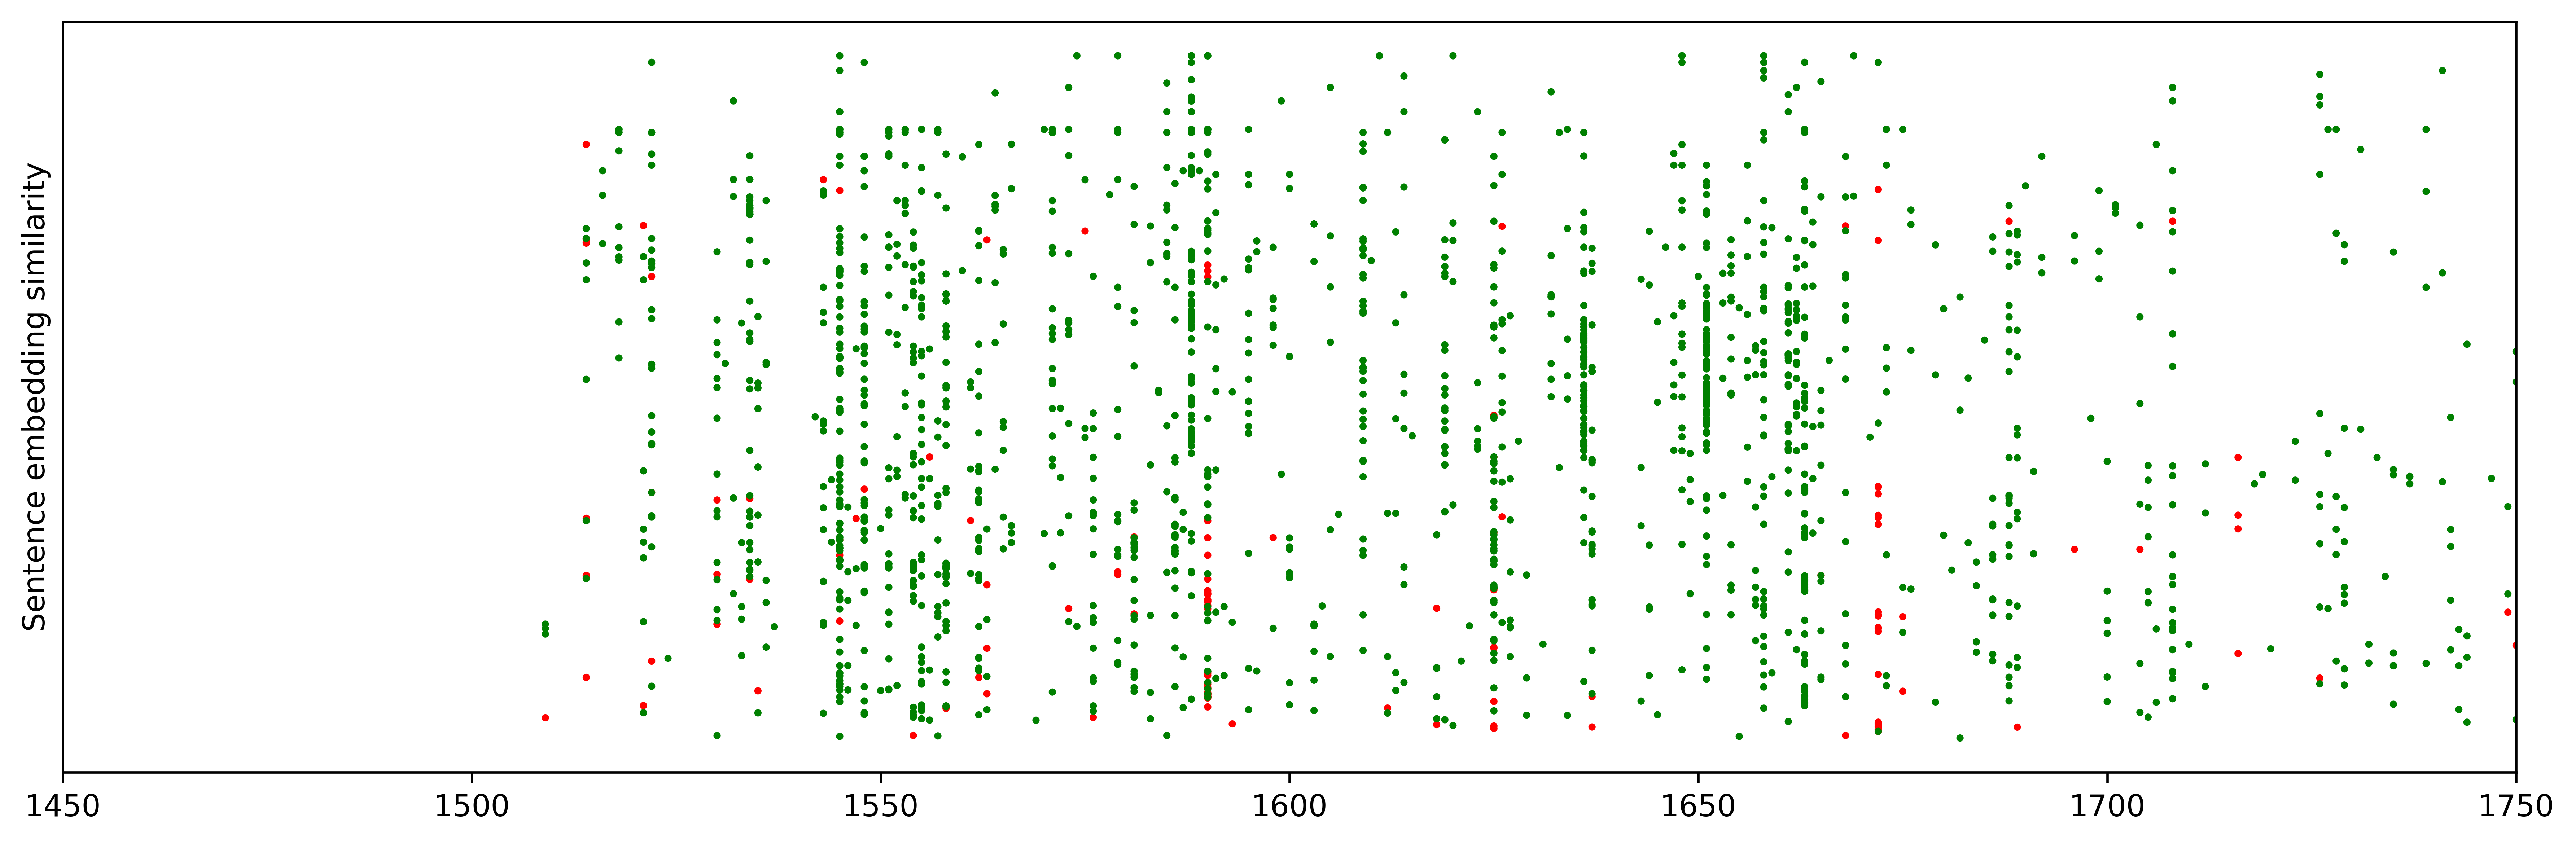

In [61]:
fig, ax = plt.subplots(tight_layout=True, dpi=600, figsize=(12,4))
ax.scatter(x=years, y=embeddings_tsne, c=colors, s=2)# You may want to adjust the size depending on your similarity matrix
ax.set_yticks([])
ax.set_ylabel("Sentence embedding similarity")
ax.set_xlim(1450, 1750)

In [62]:
xs = years
ys = [np.round(n, 2) for n in embeddings_tsne2d[:, 0]]
zs = [np.round(n, 2) for n in embeddings_tsne2d[:, 1]]

In [63]:
ys[:10]

[-15.85, 19.68, -9.19, 1.72, -3.47, -0.95, -16.81, -6.84, -35.68, 16.25]

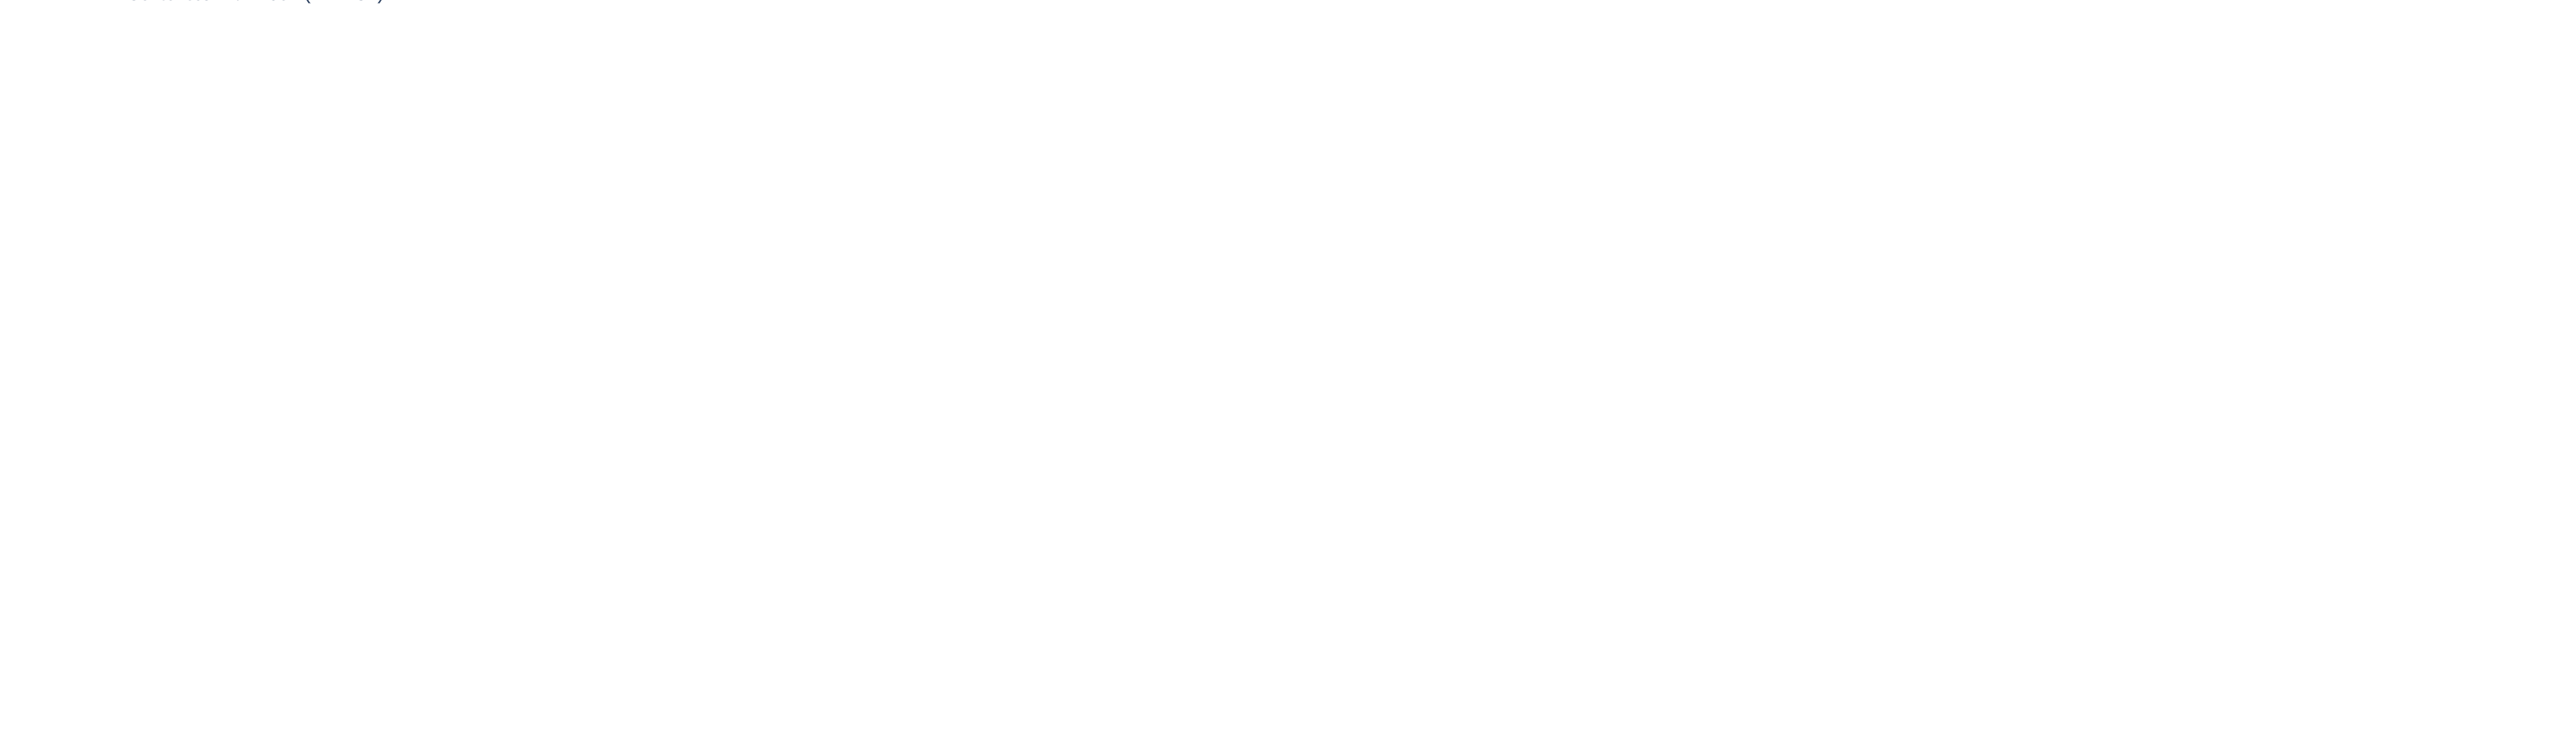

In [64]:
title = "Sentences with 'liber' (N={})".format(len(sentences))
fig = go.Figure(data=go.Scatter3d(
    x=xs,
    y=ys,
    z=zs,
    mode='markers',
    marker=dict(
        size=5,
        color=colors,
        opacity=0.8
    ),
    text=hover_text,  # use mapped hover text
    hoverinfo='text',  # ensure only the text field is displayed on hover
))

fig.update_layout(
    title=title,
    scene=dict(
        xaxis=dict(title='year', showbackground=False, showgrid=True, showline=True), #showline=True, showticklabels=True, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        #xaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        yaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        zaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        bgcolor='rgba(255,255,255,0)'
    ),
    paper_bgcolor='rgba(255,255,255,255)',  # set the color of the area around the axes
    plot_bgcolor='rgba(255,255,255,255)',  # set the color of the entire chart
    autosize=False,
    width=1000,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0)
)


In [111]:
pio.write_html(fig, file="../figures/liber-diachronic.html")

In [112]:
#html_code = pio.to_html(fig, include_plotlyjs='cdn')
#pyperclip.copy(html_code)

In [65]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=0).fit(target_embeddings)
labels = kmeans.labels_
cluster_colors = {0: "#1f77b4",  # muted blue
                  1: "#ff7f0e",  # safety orange
                  2: "#2ca02c",  # cooked asparagus green
                  3: "#d62728",  # brick red
                  4: "#9467bd"}
# colors = [cluster_colors[l] for l in labels]

In [66]:
tsne = TSNE(n_components=3, perplexity=30)
embeddings_tsne = tsne.fit_transform(np.vstack(target_vectors))

In [67]:
xs = embeddings_tsne[:, 0]
ys = embeddings_tsne[:, 1]
zs = embeddings_tsne[:, 2]

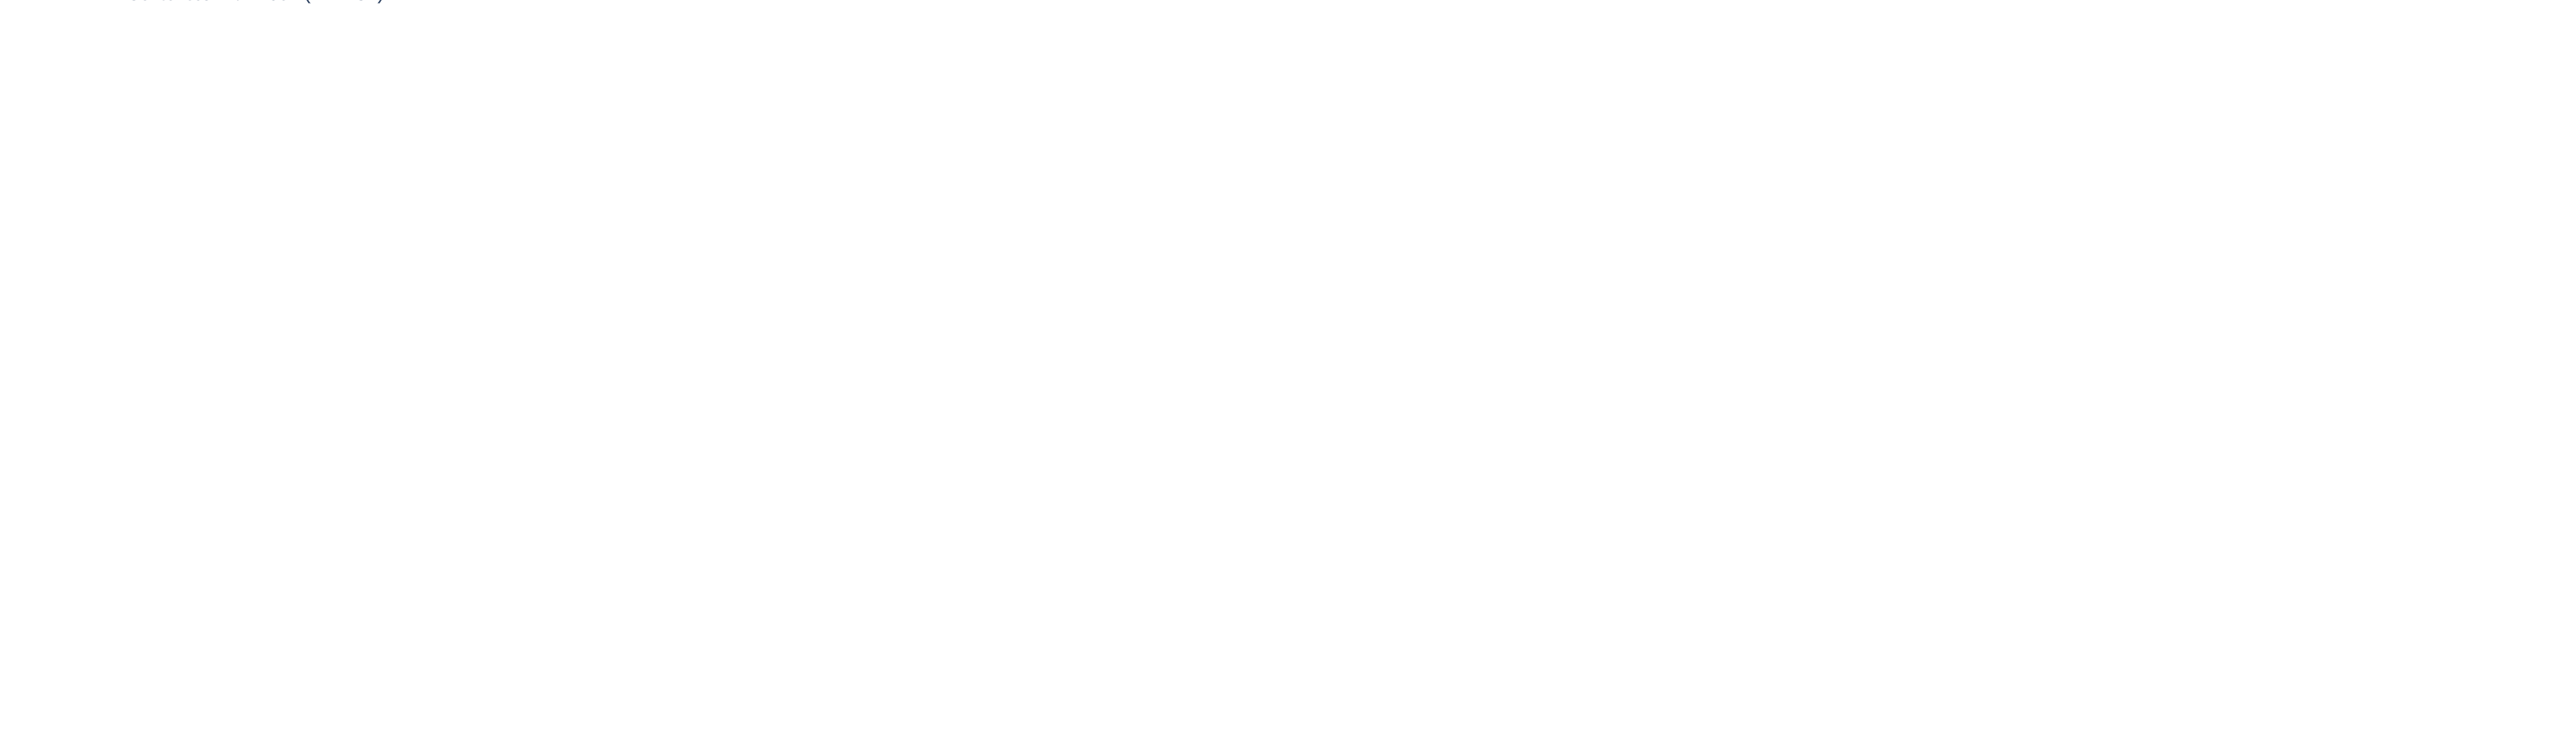

In [68]:
title = "Sentences with 'liber' (N={})".format(len(sentences))
fig = go.Figure(data=go.Scatter3d(
    x=xs,
    y=ys,
    z=zs,
    mode='markers',
    marker=dict(
        size=5,
        color=colors,
        opacity=0.8
    ),
    text=hover_text,  # use mapped hover text
    hoverinfo='text',  # ensure only the text field is displayed on hover
))

fig.update_layout(
    title=title,
    scene=dict(
        xaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        yaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        zaxis=dict(title='', showgrid=False, showline=False, showticklabels=False, zeroline=False, linecolor='rgba(0,0,0,0)', showbackground=False),
        bgcolor='rgba(255,255,255,0)'
    ),
    paper_bgcolor='rgba(255,255,255,255)',  # set the color of the area around the axes
    plot_bgcolor='rgba(255,255,255,255)',  # set the color of the entire chart
    autosize=False,
    width=1000,
    height=800,
    margin=dict(l=0, r=0, b=0, t=0)
)


In [69]:
pio.write_html(fig, file="../figures/liber-sample.html")

In [70]:
#html_code = pio.to_html(fig, include_plotlyjs='cdn')
#pyperclip.copy(html_code)

In [71]:
len(sents_dfs)

2154

### Classification

In [89]:
# load back the anotated data, directly from gspread sheet
sents_meta_anot = get_as_dataframe(liber_naturae_gs.worksheet("sents_meta_df_v1"))
sents_meta_anot.head(5)

,0,1,2,author,year,Metaphor,Cross-reference,Internal reference,Reference to Pliny the Elder - Naturalis historia,Reference to another author's work,Metaphor in natural magic (chiromancy),Metaphor in astrology/astronomy,Metaphor in natural philosophy/physics,Metaphor in medicine or botany,"Metaphor in (philosophical) theology, encyclopaedism, or bibliography",Incorrect lemma
0,637738,214,Argumentum affers quam obrem alteram ab altera...,Leoniceno,1509.0,False,True,False,True,False,False,False,False,False,False,False
1,841475,11568,Colligit Aristoteles libro naturalium tertio s...,Pio,1514.0,False,True,False,False,Aristotle,False,False,False,False,False,False
2,841475,31362,Sanctaria scrinia & secretiora repositoria Pli...,Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False
3,841475,24338,lege Senecam libro naturaliu primo.,Pio,1514.0,False,True,False,False,Seneca,False,False,False,False,False,False
4,841475,55017,"phantida foeminae, quam multa composuit, nomen...",Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False


In [90]:
# so how many metaphors do we have?
sents_meta_anot["Metaphor"].sum()

62

In [100]:
class_data = sents_dfs[:154]  #+ random.sample(sents_dfs[154:], 346)

In [101]:
class_data[0][4]

,spacy_tokens,spacy_lemma,spacy_pos,spacy_position,bert_tokens,bert_tok_emb,bert_avg_emb,bert_avg_decontext,cos_sim
0,omnes,omnis,DET,"(0, 5)",[omnes_],"[[-0.2267545, 0.03534043, -0.57197773, -0.8987...","[-0.22675450146198273, 0.03534042835235596, -0...","[-0.012650368735194206, 0.03062467835843563, -...",0.016544
1,hi,hic,DET,"(6, 8)",[hi],"[[0.065882646, 0.15884511, -0.29995036, -0.766...","[0.06588264554738998, 0.15884511172771454, -0....","[0.05322127416729927, -0.01336828712373972, -0...",0.089138
2,cum,cum,ADP,"(9, 12)",[cum],"[[-0.078728326, 0.013177161, -0.32417047, -1.1...","[-0.0787283256649971, 0.013177161104977131, -0...","[0.05187046155333519, -0.02129324898123741, 0....",0.014447
3,lanne,,NOUN,"(13, 18)","[lan, ne_]","[[-0.5393002, 0.017649591, -0.66978925, -1.107...","[-0.47358882427215576, -0.15611495077610016, -...","[0.000102214515209198, 0.019755538552999496, -...",0.086808
4,&,&,PUNCT,"(19, 20)",[&],"[[-0.098285615, 0.25577477, -0.37196028, -0.89...","[-0.09828561544418335, 0.25577476620674133, -0...","[0.053975727409124374, 0.02921023964881897, -0...",0.005627
5,Mambre,,PROPN,"(21, 27)","[mam, bre_]","[[-0.11211276, 0.24862047, -0.40294325, -1.211...","[-0.29018062353134155, 0.20940619707107544, -0...","[-0.005745686125010252, -0.022986212745308876,...",0.003742
6,et,et,CCONJ,"(28, 30)",[et],"[[-0.18621594, 0.017778393, -0.23182139, -1.04...","[-0.18621593713760376, 0.017778392881155014, -...","[0.023676078766584396, -0.015391281805932522, ...",0.065091
7,Simone,Simo,PROPN,"(31, 37)","[simo, ne_]","[[-0.5339989, 0.17992054, -0.07132285, -0.8835...","[-0.5432291626930237, -0.11695485562086105, -0...","[0.027885613963007927, -0.0015635404270142317,...",0.022789
8,mago,magus,NOUN,"(38, 42)",[mago],"[[-0.103658386, 0.119519696, -0.38165584, -0.6...","[-0.10365838557481766, 0.11951969563961029, -0...","[0.09494044631719589, -0.025257257744669914, 0...",0.058823
9,aeternis,aeternus,ADJ,"(43, 51)","[aeterni, s_]","[[-0.5825693, 0.15036915, -0.29319075, -1.0211...","[-0.5024323463439941, -0.09176509827375412, -0...","[-0.01861829124391079, 0.029625626280903816, -...",0.126318


In [102]:
target = "liber"
target_vectors = []
for sent_data in class_data:
    df = sent_data[4]
    target_row = df.loc[df["spacy_lemma"] == target].iloc[0]
    target_vectors.append(target_row['bert_avg_emb'])

In [104]:
### Y = 154 * [1] + 346 * [0] 

y_anotated = sents_meta_anot["Metaphor"].apply(lambda x: 1 if x else 0).tolist()
Y = y_anotated # + 346 * [0] 
Y

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0]

In [105]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [107]:
len(target_vectors)

154

In [108]:
len(Y)

154

In [109]:
X_trainval, X_test, Y_trainval, Y_test = train_test_split(target_vectors, Y, test_size=0.2, random_state=42, stratify=Y)

In [110]:
# Split train into train-val
X_train, X_val, Y_train, Y_val = train_test_split(X_trainval, Y_trainval, test_size=0.2, random_state=42,
                                                  stratify=Y_trainval)

In [113]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

LogisticRegression(max_iter=1000)

In [114]:
# Predict probabilities
Y_pred_proba = model.predict_proba(X_val)
Y_pred_proba

array([[0.49584108, 0.50415892],
       [0.44774062, 0.55225938],
       [0.97469671, 0.02530329],
       [0.01558113, 0.98441887],
       [0.28855919, 0.71144081],
       [0.58499528, 0.41500472],
       [0.91452307, 0.08547693],
       [0.38044211, 0.61955789],
       [0.18917185, 0.81082815],
       [0.07154985, 0.92845015],
       [0.26157172, 0.73842828],
       [0.92607911, 0.07392089],
       [0.85027093, 0.14972907],
       [0.05408494, 0.94591506],
       [0.92632414, 0.07367586],
       [0.72466083, 0.27533917],
       [0.99055796, 0.00944204],
       [0.4208823 , 0.5791177 ],
       [0.11520987, 0.88479013],
       [0.95689953, 0.04310047],
       [0.07463577, 0.92536423],
       [0.22153638, 0.77846362],
       [0.55196967, 0.44803033],
       [0.63374265, 0.36625735],
       [0.11348027, 0.88651973]])

In [ ]:
# Predict probabilities
Y_pred_proba = model.predict_proba(X_val)

# Get probabilities of the positive class (assuming binary classification)
Y_pred_proba_positive_class = Y_pred_proba[:, 1]

In [111]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

Y_pred = model.predict(X_val)

print('Validation Accuracy: ', accuracy_score(Y_val, Y_pred))
print('\nClassification Report:\n', classification_report(Y_val, Y_pred))

Validation Accuracy:  0.6

Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.53      0.62        15
           1       0.50      0.70      0.58        10

    accuracy                           0.60        25
   macro avg       0.61      0.62      0.60        25
weighted avg       0.64      0.60      0.60        25



In [112]:
Y_pred

array([1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       0, 0, 1])

In [127]:
model = LogisticRegression(max_iter=1000) # increasing max_iter to ensure convergence
model.fit(X_train, Y_train)

Y_pred = model.predict(X_val)

print('Validation Accuracy: ', accuracy_score(Y_val, Y_pred))
print('\nClassification Report:\n', classification_report(Y_val, Y_pred))

Validation Accuracy:  0.9125

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.91      0.93        55
           1       0.82      0.92      0.87        25

    accuracy                           0.91        80
   macro avg       0.89      0.91      0.90        80
weighted avg       0.92      0.91      0.91        80



[Text(0, 0.5, 'liber\n(random)'), Text(0, 1.5, 'liber\nnaturae')]

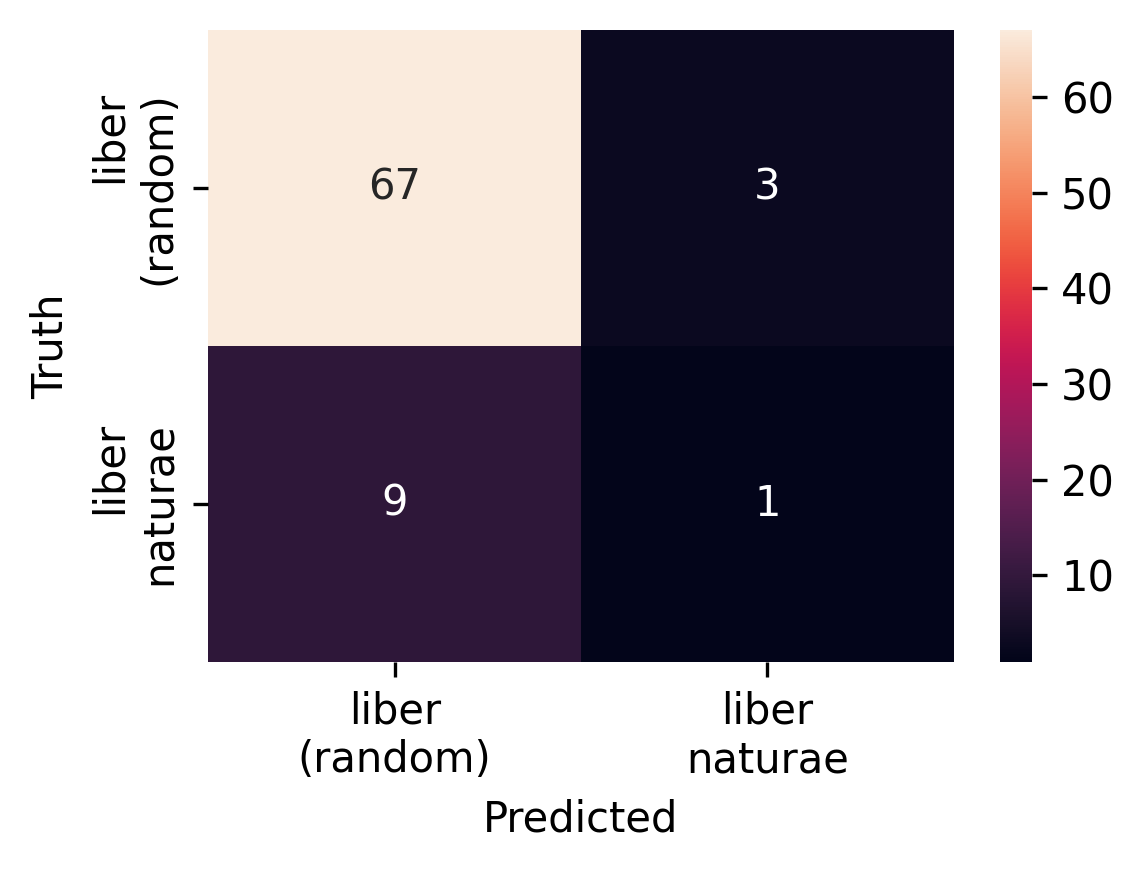

In [99]:
cm = confusion_matrix(Y_val, Y_pred)

fig, ax = plt.subplots(tight_layout=True, dpi=300, figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Truth')
ax.set_xticklabels(["liber\n(random)", "liber\nnaturae"])
ax.set_yticklabels(["liber\n(random)", "liber\nnaturae"])


[Text(0, 0.5, 'liber\n(random)'), Text(0, 1.5, 'liber\nnaturae')]

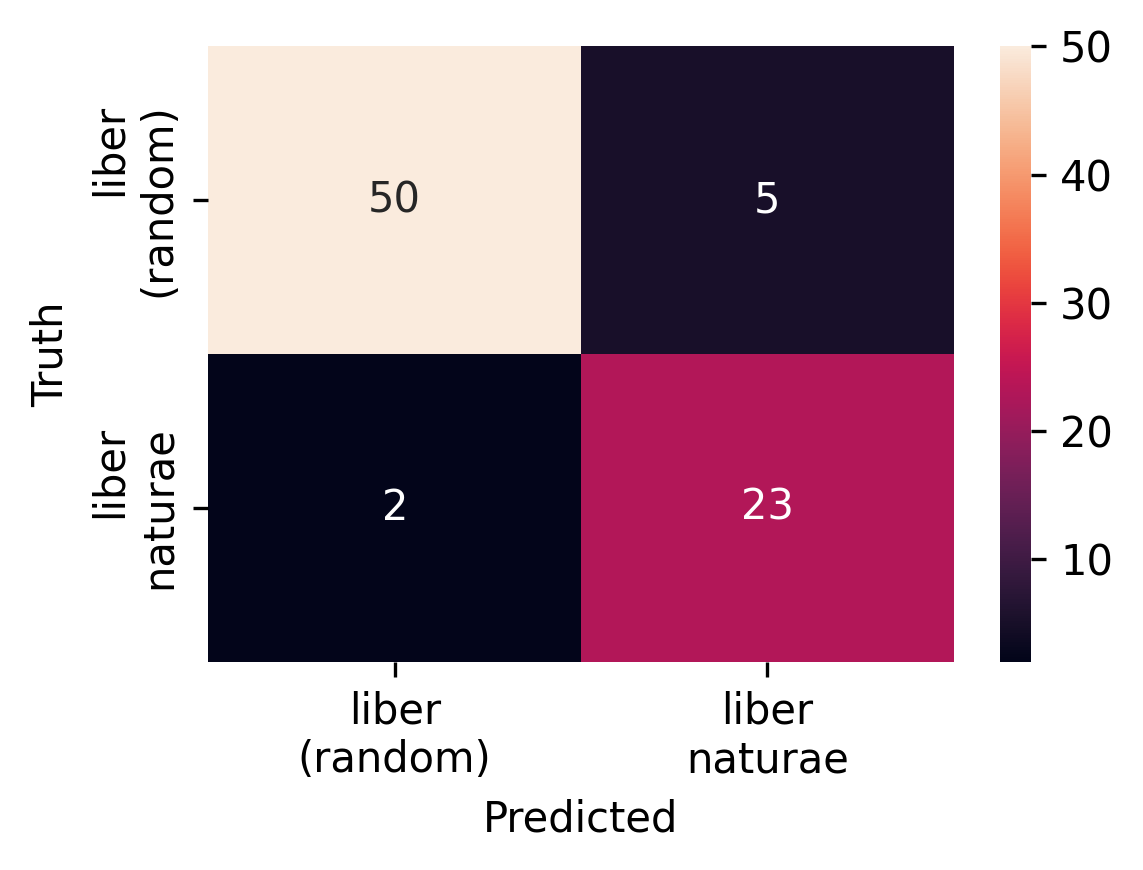

In [128]:
cm = confusion_matrix(Y_val, Y_pred)

fig, ax = plt.subplots(tight_layout=True, dpi=300, figsize=(4,3))
sns.heatmap(cm, annot=True, fmt='d', ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Truth')
ax.set_xticklabels(["liber\n(random)", "liber\nnaturae"])
ax.set_yticklabels(["liber\n(random)", "liber\nnaturae"])


In [129]:
fig.savefig("../figures/liber-confussion-matrix_v1.png")

### Loading back the annotated data

In [38]:
# load back the anotated data, directly from gspread sheet
sents_meta_anot = get_as_dataframe(liber_naturae_gs.worksheet("sents_meta_df_v1"))

In [39]:
sents_meta_anot.head(5)

,0,1,2,author,year,Metaphor,Cross-reference,Internal reference,Reference to Pliny the Elder - Naturalis historia,Reference to another author's work,Metaphor in natural magic (chiromancy),Metaphor in astrology/astronomy,Metaphor in natural philosophy/physics,Metaphor in medicine or botany,"Metaphor in (philosophical) theology, encyclopaedism, or bibliography",Incorrect lemma
0,637738,214,Argumentum affers quam obrem alteram ab altera...,Leoniceno,1509.0,False,True,False,True,False,False,False,False,False,False,False
1,841475,11568,Colligit Aristoteles libro naturalium tertio s...,Pio,1514.0,False,True,False,False,Aristotle,False,False,False,False,False,False
2,841475,31362,Sanctaria scrinia & secretiora repositoria Pli...,Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False
3,841475,24338,lege Senecam libro naturaliu primo.,Pio,1514.0,False,True,False,False,Seneca,False,False,False,False,False,False
4,841475,55017,"phantida foeminae, quam multa composuit, nomen...",Pio,1514.0,False,True,False,True,False,False,False,False,False,False,False


In [41]:
len(sents_meta_anot)

154

In [40]:
# so how many metaphors do we have?
sents_meta_anot["Metaphor"].sum()

62